# Decision tree: loan approval rules

Part of the ML Portfolio Model Zoo. Educational purposes only.

Given credit score, income, loan size relative to income, job tenure and collateral, predict whether a loan application is approved, using a tree whose rules can be read. The data is **synthetic**, generated from a banker's rule of thumb with 6% noise.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

# Everything here reuses train.py, so the notebook and the site always use the same pipeline.

## Data

In [2]:
data = make_data()
print(data.shape)
data.head()

(5000, 6)


,credit_score,annual_income_k,loan_to_income_pct,employment_years,collateral,target
0,686.0,57.0,44.0,9.0,property,1
1,572.0,56.0,20.0,14.0,property,0
2,724.0,46.0,14.0,7.0,none,1
3,740.0,81.0,64.0,2.0,none,1
4,494.0,73.0,88.0,2.0,none,0


In [3]:
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
credit_score,5000.0,NaN,NaN,NaN,657.911,83.920384,350.0,601.0,660.0,714.0,850.0
annual_income_k,5000.0,NaN,NaN,NaN,73.6714,38.791076,15.0,47.0,64.0,91.0,250.0
loan_to_income_pct,5000.0,NaN,NaN,NaN,45.1244,25.59095,5.0,26.0,40.0,59.0,120.0
employment_years,5000.0,NaN,NaN,NaN,6.0092,4.222829,0.0,3.0,5.0,8.0,30.0
collateral,5000,3,none,2494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,5000.0,NaN,NaN,NaN,0.4434,0.496836,0.0,0.0,0.0,1.0,1.0


## Train and evaluate

`train_and_evaluate()` fits the scikit-learn pipeline, scores it on a held-out split, exports it to ONNX and asserts that onnxruntime reproduces scikit-learn's predictions.

In [4]:
result = train_and_evaluate()
print(f"accuracy {result.metrics['accuracy']:.3f}   ROC AUC {result.metrics['roc_auc']:.3f}")
print(f"majority-class baseline {result.metrics['majority_baseline']:.3f}")
print(f"ONNX vs sklearn max abs diff: {result.metrics['onnx_max_abs_diff']:.1e}")

accuracy 0.932   ROC AUC 0.934
majority-class baseline 0.557
ONNX vs sklearn max abs diff: 2.2e-08


## Charts

The same charts the site shows, written to a temporary folder.

The learned tree (top two levels): each box is a yes/no question about the applicant.


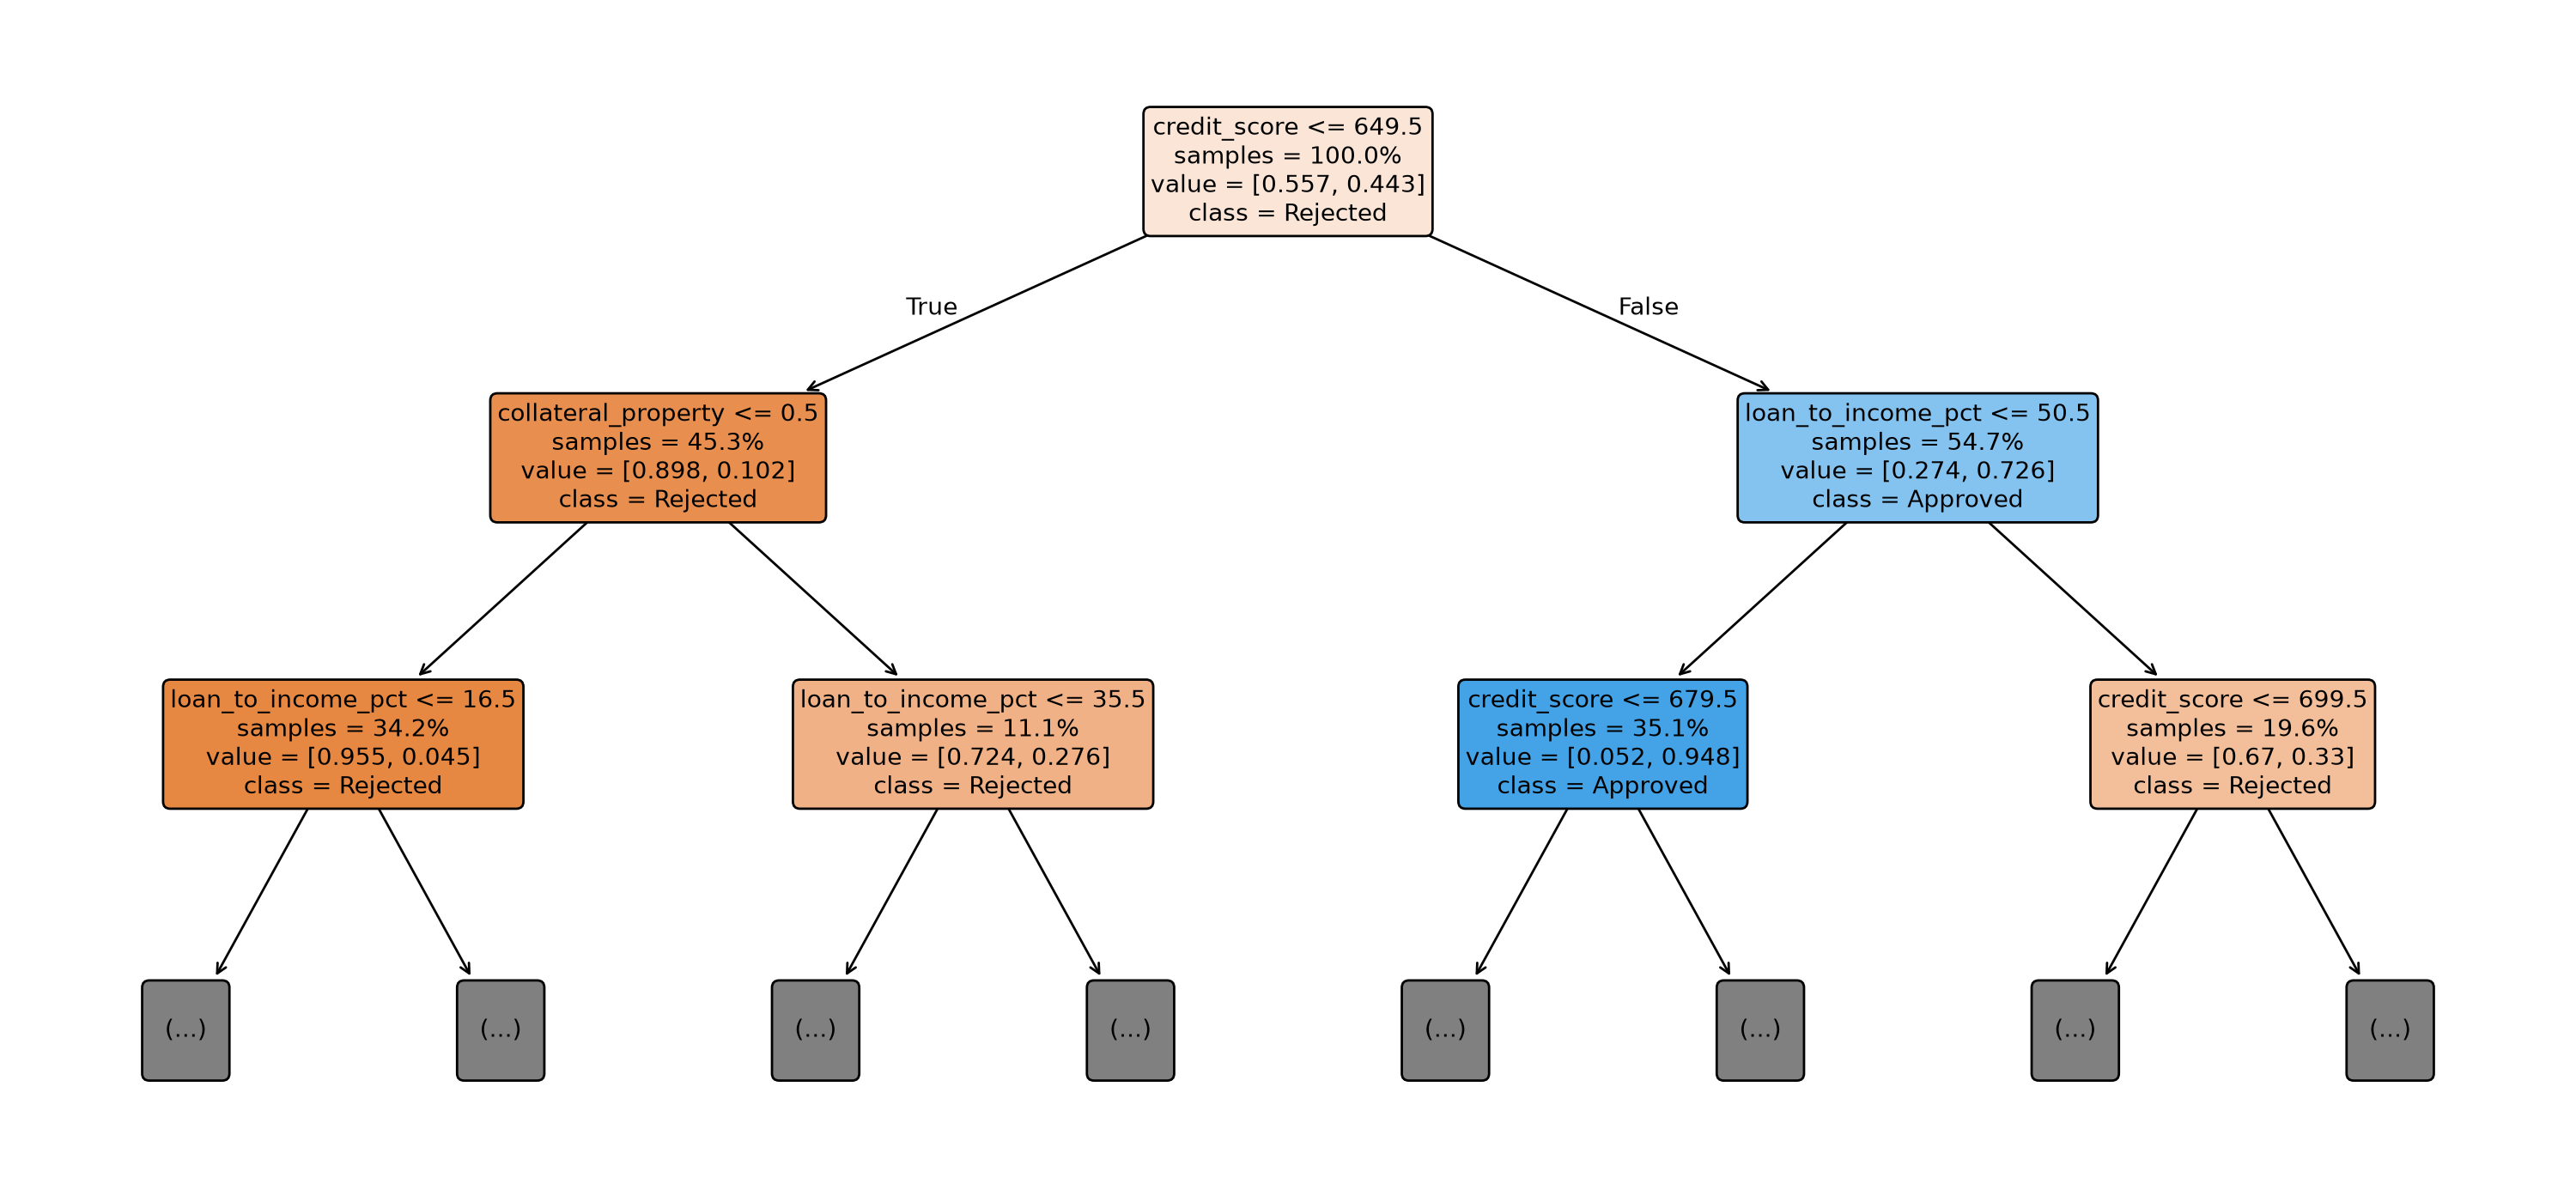

Which questions the tree relies on most when deciding.


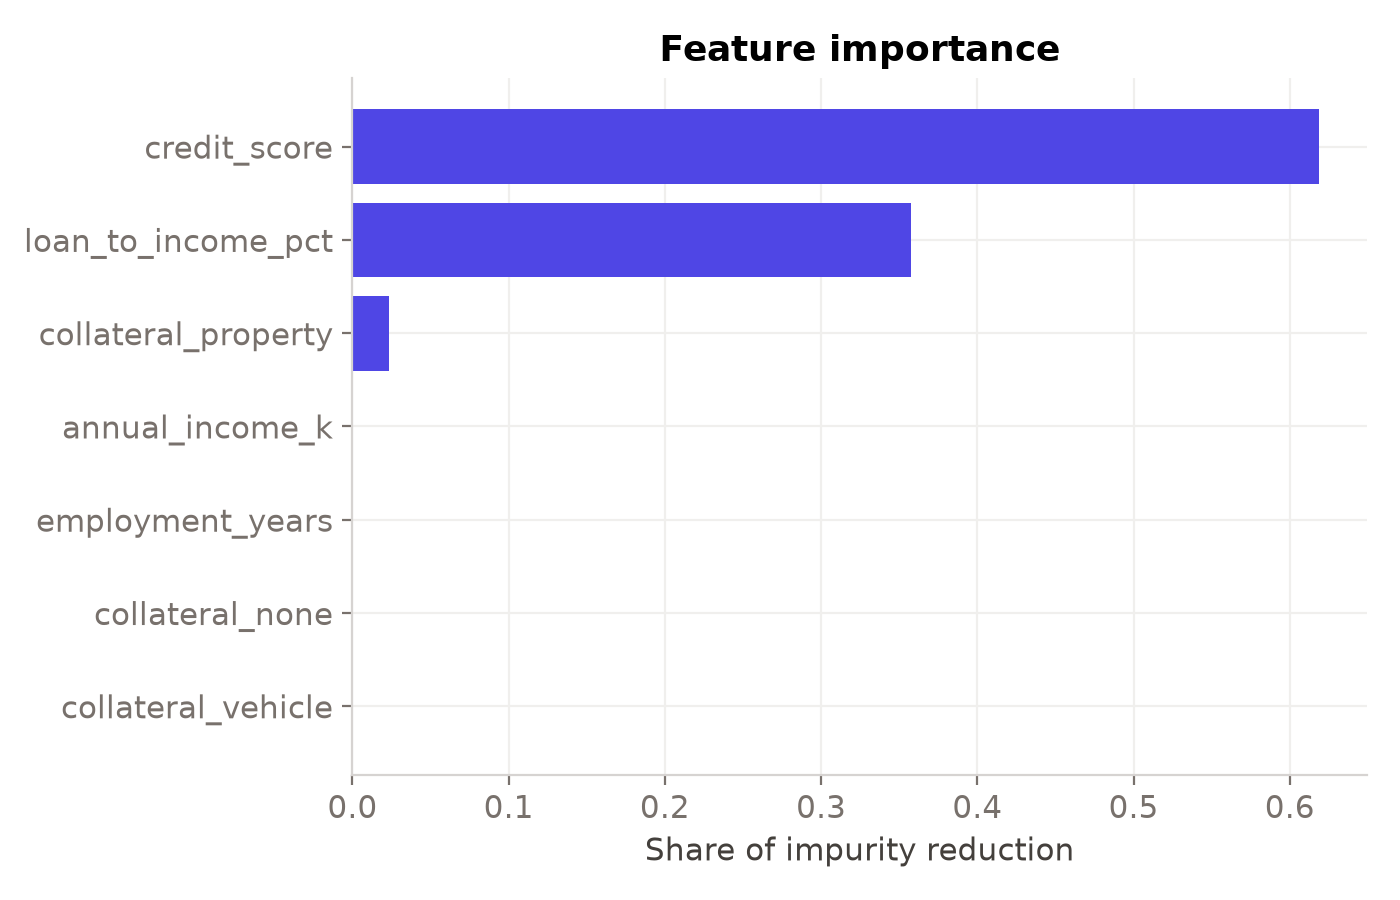

Deeper trees memorise the training data; held-out accuracy stops improving early.


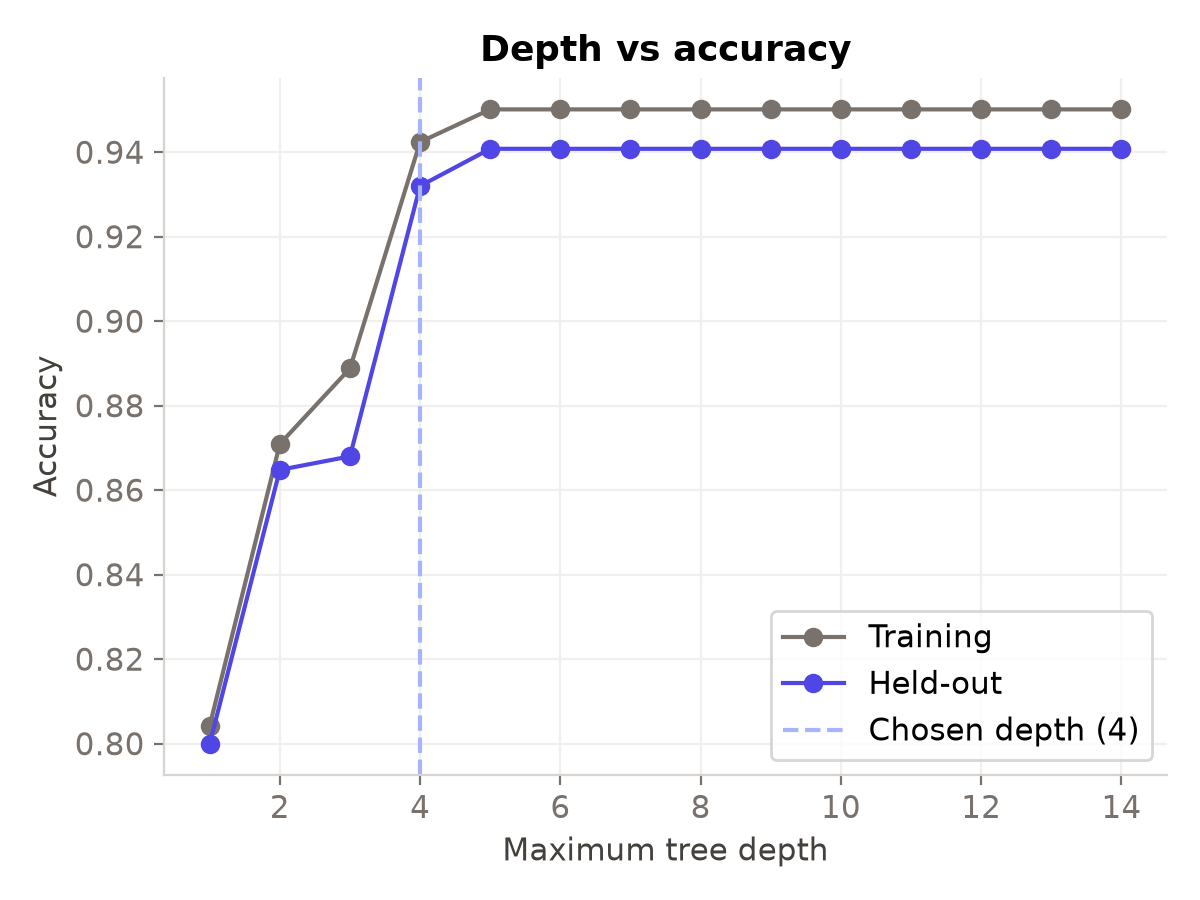

Confusion matrix on held-out data.


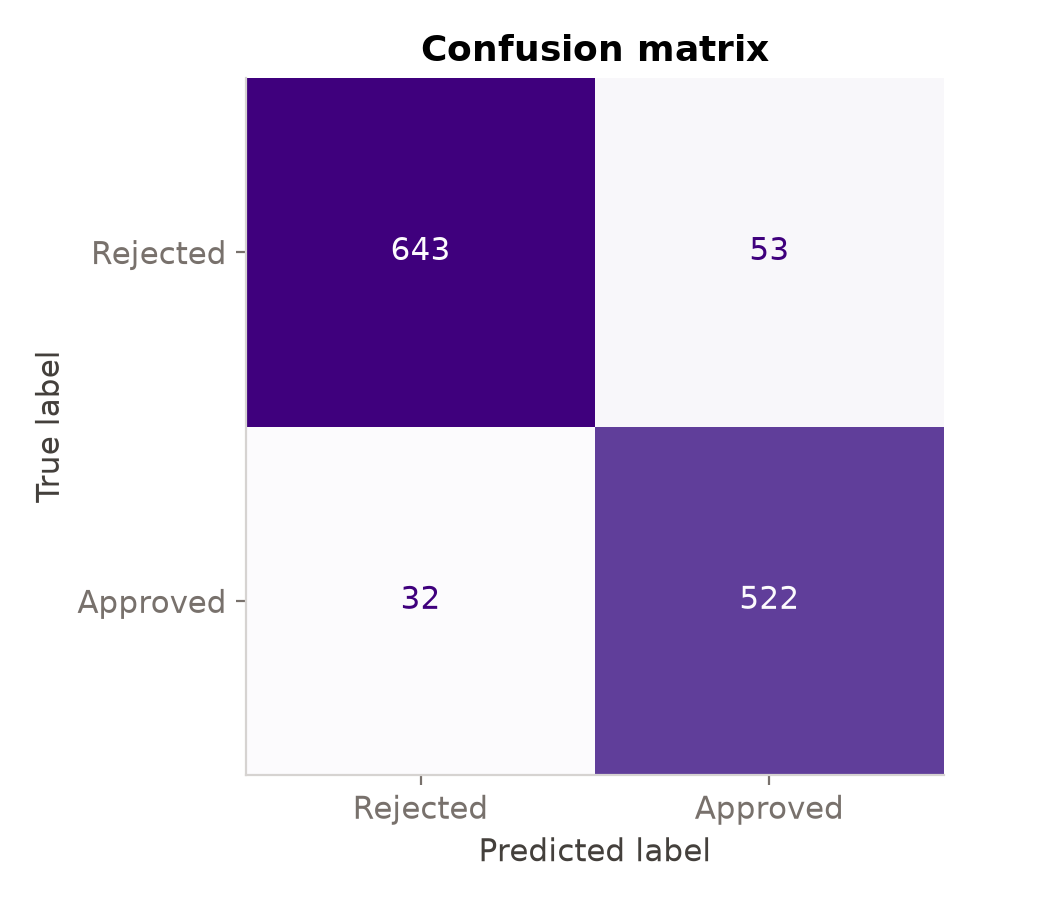

In [5]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## Predict with the exported ONNX model

In [6]:
example = pd.DataFrame([PRESETS[1]["values"]])[ALL_COLUMNS]
_, probs = onnx_predict(result.model_bytes, example)
print("Weak applicant ->", LABELS[int(probs[0].argmax())], f"(P(approved) = {probs[0][1]:.1%})")

Weak applicant -> Rejected (P(approved) = 5.6%)


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app. See the README for details.